# Levi's Demand Forecasting — Location × SKU

## 1. Project Objective

The goal is to forecast the next 4 weeks of Net Sold Quantity for each fulfilment location and SKU.

- **Dataset:** Levi's
- **Forecast level:** Fulfilment Location × SKU Code
- **Time interval:** Weekly
- **Target variable:** Net Sold Quantity
- **Forecast horizon:** 4 weeks

We will begin with a simple baseline model, evaluate its accuracy on historical data, and then compare it with more advanced models.

## 2. Load and Inspect Prepared Data

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Locate the processed data folder
project_root = Path.cwd().parent
processed_folder = project_root / "data" / "processed"

# Load Levi's weekly-filled data
file_path = processed_folder / "levis_Order_data_cleaned_weekly_filled.csv"
df = pd.read_csv(file_path, low_memory=False)

# Convert Week to datetime
df["Week"] = pd.to_datetime(df["Week"])

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nDate range:", df["Week"].min(), "to", df["Week"].max())
print("Locations:", df["Fulfilment Location"].nunique())
print("SKUs:", df["SKU Code"].nunique())

Dataset shape: (7631, 4)

First 5 rows:
        Week           Fulfilment Location      SKU Code  Net Sold Quantity
0 2026-02-23  Adonis-City Centre Mangalore   004OK-0005S                1.0
1 2026-02-09     Chintamani-Panjim New Goa   004OK-0005L                1.0
2 2026-02-09     Chintamani-Panjim New Goa  004OK-0005XL                1.0
3 2026-02-16                  Chrompet New   16960-1444S                1.0
4 2026-02-09              Didymous-Citadel   004LZ-0030S                1.0

Date range: 2024-08-05 00:00:00 to 2026-02-23 00:00:00
Locations: 27
SKUs: 183


## 3. Select One Location-SKU Combination

We will study the weekly demand history of one SKU at one fulfilment location before forecasting its future demand.

In [2]:
# Find the location-SKU combinations with the most recorded demand
combo_summary = (
    df.groupby(["Fulfilment Location", "SKU Code"])
    .agg(
        total_quantity=("Net Sold Quantity", "sum"),
        weeks=("Week", "nunique")
    )
    .reset_index()
)

# Start with the combination having the most total quantity
combo_summary = combo_summary.sort_values(
    "total_quantity", ascending=False
)

print(combo_summary.head(10).to_string(index=False))

Fulfilment Location       SKU Code  total_quantity  weeks
    South Warehouse 18298-18413232          4694.0     12
    South Warehouse    16960-1444M          4596.0     14
    South Warehouse    004OK-0005L          4422.0      7
    South Warehouse    16960-1444L          4415.0     14
    South Warehouse    004JH-0072L          4271.0      4
    South Warehouse    004JH-0072M          4214.0      4
    South Warehouse    004LZ-0030L          4166.0      7
    South Warehouse 18298-18413432          4145.0     12
    South Warehouse    004LZ-0030M          3933.0      7
    South Warehouse    004OK-0005M          3923.0      7


Location: South Warehouse
SKU: 18298-18413232
Number of weeks: 12


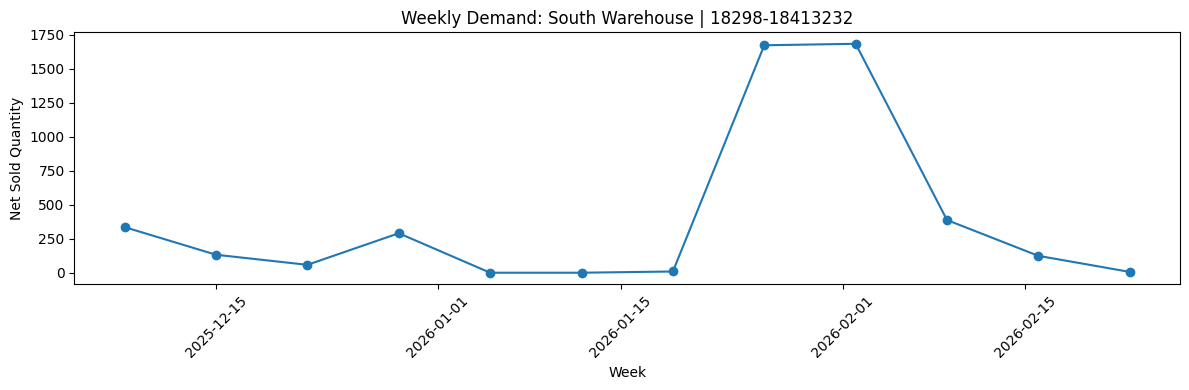

In [3]:
# Select the top location-SKU combination
location = combo_summary.iloc[0]["Fulfilment Location"]
sku = combo_summary.iloc[0]["SKU Code"]

# Get its weekly demand history
series = df[
    (df["Fulfilment Location"] == location) &
    (df["SKU Code"] == sku)
].sort_values("Week").copy()

print("Location:", location)
print("SKU:", sku)
print("Number of weeks:", len(series))

plt.figure(figsize=(12, 4))
plt.plot(series["Week"], series["Net Sold Quantity"], marker="o")
plt.title(f"Weekly Demand: {location} | {sku}")
plt.xlabel("Week")
plt.ylabel("Net Sold Quantity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [4]:
# Display the weekly demand values
print(
    series[["Week", "Net Sold Quantity"]]
    .to_string(index=False)
)

# Check whether any calendar weeks are missing
all_weeks = pd.date_range(
    start=series["Week"].min(),
    end=series["Week"].max(),
    freq="7D"
)

print("\nExpected weeks:", len(all_weeks))
print("Available weeks:", len(series))
print("Missing weeks:", len(all_weeks) - len(series))

      Week  Net Sold Quantity
2025-12-08              335.0
2025-12-15              132.0
2025-12-22               58.0
2025-12-29              290.0
2026-01-05                0.0
2026-01-12                0.0
2026-01-19                9.0
2026-01-26             1671.0
2026-02-02             1682.0
2026-02-09              387.0
2026-02-16              124.0
2026-02-23                6.0

Expected weeks: 12
Available weeks: 12
Missing weeks: 0


data tells us
Period	Net sold quantity
Dec 8–29, 2025	335, 132, 58, 290
Jan 5–19, 2026	0, 0, 9
Jan 26–Feb 2, 2026	1,671, 1,682
Feb 9–23, 2026	387, 124, 6
The two weeks with 1,671 and 1,682 units account for a large share of the total 4,694 units.
This creates a forecasting challenge: if we simply average all weeks, the forecast might be too high for normal weeks. If we ignore the spikes, we might underestimate demand if those large orders are recurring.
We should keep these values unchanged for now and evaluate our forecasting method against historical data.

## 5. Create a Simple Baseline Forecast

We will use the average demand from the previous 4 weeks to predict the next week. We will first test this method on historical data before using it to forecast future demand.

In [5]:

# Use the last 4 weeks to predict the next week
last_4_weeks = series["Net Sold Quantity"].tail(4)

baseline_forecast = last_4_weeks.mean()

print("Demand in the last 4 weeks:")
print(last_4_weeks.to_list())

print("\nBaseline forecast for the next week:", round(baseline_forecast, 2))


Demand in the last 4 weeks:
[1682.0, 387.0, 124.0, 6.0]

Baseline forecast for the next week: 549.75


## 6. Evaluate the Baseline Model

We will test our baseline on the last 4 historical weeks. For each week, the prediction will be the average demand of the previous 4 weeks. We will compare predictions with actual demand using Mean Absolute Error (MAE).

In [7]:

# Keep the data in chronological order
values = series["Net Sold Quantity"].to_list()
weeks = series["Week"].to_list()

actual = []
predicted = []
test_weeks = []

# Predict each of the last 4 weeks
for i in range(len(values) - 4, len(values)):
    prediction = sum(values[i-4:i]) / 4

    predicted.append(prediction)
    actual.append(values[i])
    test_weeks.append(weeks[i])

# Show actual vs predicted demand
results = pd.DataFrame({
    "Week": test_weeks,
    "Actual": actual,
    "Predicted": predicted
})

results["Absolute Error"] = abs(
    results["Actual"] - results["Predicted"]
)

print(results.to_string(index=False))

# Calculate Mean Absolute Error
mae = results["Absolute Error"].mean()

print("\nMean Absolute Error (MAE):", round(mae, 2))


      Week  Actual  Predicted  Absolute Error
2026-02-02  1682.0     420.00         1262.00
2026-02-09   387.0     840.50          453.50
2026-02-16   124.0     937.25          813.25
2026-02-23     6.0     966.00          960.00

Mean Absolute Error (MAE): 872.19


second baseline: previous week's demand
This is called the naive forecast. It assumes next week's demand will equal this week's demand.
For example, if this week had 124 units, the prediction for next week is 124 units.
Let's compare it with our four-week-average baseline using the same test weeks.

## 7. Compare with a Naive Forecast

The naive forecast predicts that the next week's demand will equal the current week's demand. We will evaluate it on the same historical test weeks and compare its MAE with the four-week-average baseline.

In [8]:

# Predict each test week using the previous week's demand
naive_predicted = []

for i in range(len(values) - 4, len(values)):
    naive_predicted.append(values[i - 1])

# Calculate absolute errors
naive_errors = [
    abs(actual[i] - naive_predicted[i])
    for i in range(len(actual))
]

# Add results to the existing table
results["Naive Predicted"] = naive_predicted
results["Naive Absolute Error"] = naive_errors

print(results.to_string(index=False))

naive_mae = sum(naive_errors) / len(naive_errors)

print("\nFour-week-average MAE:", round(mae, 2))
print("Naive forecast MAE:", round(naive_mae, 2))


      Week  Actual  Predicted  Absolute Error  Naive Predicted  Naive Absolute Error
2026-02-02  1682.0     420.00         1262.00           1671.0                  11.0
2026-02-09   387.0     840.50          453.50           1682.0                1295.0
2026-02-16   124.0     937.25          813.25            387.0                 263.0
2026-02-23     6.0     966.00          960.00            124.0                 118.0

Four-week-average MAE: 872.19
Naive forecast MAE: 421.75


The naive forecast's MAE is about 52% lower than the four-week-average model's MAE.                                   We're testing only one SKU at one location across four weeks. We cannot conclude that the naive forecast will perform best for all 353 location-SKU combinations. We'll need to evaluate across more combinations before selecting a model for the project

## 8. Generate a Simple 4-Week Forecast

We will use the naive forecasting method to generate an initial 4-week forecast. This is a baseline example, not the final selected model.

In [9]:

# Get the most recent actual demand
last_value = values[-1]

# Generate forecasts for the next 4 weeks
future_weeks = pd.date_range(
    start=series["Week"].max() + pd.Timedelta(days=7),
    periods=4,
    freq="7D"
)

future_forecast = pd.DataFrame({
    "Week": future_weeks,
    "Forecast Net Sold Quantity": [last_value] * 4
})

print(future_forecast.to_string(index=False))


      Week  Forecast Net Sold Quantity
2026-03-02                         6.0
2026-03-09                         6.0
2026-03-16                         6.0
2026-03-23                         6.0


## 9. Evaluate Baseline Models Across Location-SKU Combinations

We will evaluate the naive forecast and four-week-average forecast across multiple location-SKU combinations.

For each combination, we will use the last 4 historical weeks for testing and only use earlier weeks to make predictions. We will compare the models using MAE.

In [10]:

# Evaluate both models across all location-SKU combinations

evaluation_results = []

for (loc, sku), group in df.groupby(
    ["Fulfilment Location", "SKU Code"]
):
    group = group.sort_values("Week")
    values = group["Net Sold Quantity"].to_list()

    # Need at least 8 weeks:
    # 4 weeks for history + 4 weeks for testing
    if len(values) < 8:
        continue

    actual = []
    naive_predictions = []
    average_predictions = []

    # Test on the last 4 weeks
    for i in range(len(values) - 4, len(values)):
        actual.append(values[i])

        # Predict using the previous week's demand
        naive_predictions.append(values[i - 1])

        # Predict using the previous 4 weeks' average
        average_predictions.append(
            sum(values[i-4:i]) / 4
        )

    # Calculate MAE for this combination
    naive_mae = sum(
        abs(a - p)
        for a, p in zip(actual, naive_predictions)
    ) / 4

    average_mae = sum(
        abs(a - p)
        for a, p in zip(actual, average_predictions)
    ) / 4

    evaluation_results.append({
        "Location": loc,
        "SKU": sku,
        "Weeks": len(values),
        "Naive MAE": naive_mae,
        "4-Week Average MAE": average_mae
    })

# Convert results into a table
evaluation_df = pd.DataFrame(evaluation_results)

print("Combinations evaluated:", len(evaluation_df))

print("\nAverage MAE across combinations:")
print(
    evaluation_df[["Naive MAE", "4-Week Average MAE"]]
    .mean()
    .round(2)
)

# Count how often each model performs better
print("\nNaive model wins:",
      (evaluation_df["Naive MAE"] <
       evaluation_df["4-Week Average MAE"]).sum())

print("Four-week-average model wins:",
      (evaluation_df["4-Week Average MAE"] <
       evaluation_df["Naive MAE"]).sum())

# Save evaluation results
output_folder = project_root / "outputs"
output_folder.mkdir(parents=True, exist_ok=True)

evaluation_df.to_csv(
    output_folder / "levis_sku_model_evaluation.csv",
    index=False
)

print("\nEvaluation results saved.")


Combinations evaluated: 239

Average MAE across combinations:
Naive MAE             14.53
4-Week Average MAE    26.33
dtype: float64

Naive model wins: 104
Four-week-average model wins: 81

Evaluation results saved.


## 10. Generate 4-Week Forecasts for All Levi's Location-SKU Combinations

We will use the naive baseline to forecast the next 4 weeks for every location-SKU combination. Each combination's most recent observed demand will be used for all 4 forecast weeks.

In [11]:

# Generate future forecasts for all location-SKU combinations

forecast_rows = []

for (loc, sku), group in df.groupby(
    ["Fulfilment Location", "SKU Code"]
):
    group = group.sort_values("Week")

    # Most recent observed quantity for this combination
    last_value = group["Net Sold Quantity"].iloc[-1]
    last_week = group["Week"].max()

    # Forecast the next 4 weeks
    future_weeks = pd.date_range(
        start=last_week + pd.Timedelta(days=7),
        periods=4,
        freq="7D"
    )

    for week in future_weeks:
        forecast_rows.append({
            "Week": week,
            "Fulfilment Location": loc,
            "SKU Code": sku,
            "Forecast Net Sold Quantity": last_value
        })

forecast_df = pd.DataFrame(forecast_rows)

# Save forecasts
forecast_path = output_folder / "levis_sku_4_week_forecast.csv"
forecast_df.to_csv(forecast_path, index=False)

print("Forecast rows:", len(forecast_df))
print("Unique locations:", forecast_df["Fulfilment Location"].nunique())
print("Unique SKUs:", forecast_df["SKU Code"].nunique())
print("\nFirst 10 forecast rows:")
print(forecast_df.head(10).to_string(index=False))
print("\nSaved to:", forecast_path)


Forecast rows: 1412
Unique locations: 27
Unique SKUs: 183

First 10 forecast rows:
      Week          Fulfilment Location     SKU Code  Forecast Net Sold Quantity
2026-03-02 Adonis-City Centre Mangalore  004OK-0005S                         1.0
2026-03-09 Adonis-City Centre Mangalore  004OK-0005S                         1.0
2026-03-16 Adonis-City Centre Mangalore  004OK-0005S                         1.0
2026-03-23 Adonis-City Centre Mangalore  004OK-0005S                         1.0
2026-02-16    Chintamani-Panjim New Goa  004OK-0005L                         1.0
2026-02-23    Chintamani-Panjim New Goa  004OK-0005L                         1.0
2026-03-02    Chintamani-Panjim New Goa  004OK-0005L                         1.0
2026-03-09    Chintamani-Panjim New Goa  004OK-0005L                         1.0
2026-02-16    Chintamani-Panjim New Goa 004OK-0005XL                         1.0
2026-02-23    Chintamani-Panjim New Goa 004OK-0005XL                         1.0

Saved to: c:\Users\Manvi\

In [12]:

# Use one common forecast horizon for all combinations

forecast_start = df["Week"].max() + pd.Timedelta(days=7)

future_weeks = pd.date_range(
    start=forecast_start,
    periods=4,
    freq="7D"
)

forecast_rows = []

for (loc, sku), group in df.groupby(
    ["Fulfilment Location", "SKU Code"]
):
    group = group.sort_values("Week")

    # Use the latest available quantity for this combination
    last_value = group["Net Sold Quantity"].iloc[-1]

    for week in future_weeks:
        forecast_rows.append({
            "Week": week,
            "Fulfilment Location": loc,
            "SKU Code": sku,
            "Forecast Net Sold Quantity": last_value
        })

forecast_df = pd.DataFrame(forecast_rows)

# Save the corrected forecast
forecast_path = output_folder / "levis_sku_4_week_forecast.csv"
forecast_df.to_csv(forecast_path, index=False)

print("Forecast rows:", len(forecast_df))
print("Forecast dates:", sorted(forecast_df["Week"].unique()))
print("Unique location-SKU combinations:",
      forecast_df.groupby(
          ["Fulfilment Location", "SKU Code"]
      ).ngroups)
print("\nSaved to:", forecast_path)


Forecast rows: 1412
Forecast dates: [Timestamp('2026-03-02 00:00:00'), Timestamp('2026-03-09 00:00:00'), Timestamp('2026-03-16 00:00:00'), Timestamp('2026-03-23 00:00:00')]
Unique location-SKU combinations: 353

Saved to: c:\Users\Manvi\OneDrive\Desktop\demand_forecasting\outputs\levis_sku_4_week_forecast.csv


In [13]:
print(
    forecast_df.groupby("Week")["Fulfilment Location"]
    .nunique()
)

Week
2026-03-02    27
2026-03-09    27
2026-03-16    27
2026-03-23    27
Name: Fulfilment Location, dtype: int64


In [3]:
from pathlib import Path
import pandas as pd

# Set project folders
project_root = Path.cwd().parent
processed_folder = project_root / "data" / "processed"

# Load Levi's cleaned dataset
raw_path = processed_folder / "levis_Order_data_cleaned.csv"
levis_df = pd.read_csv(raw_path, low_memory=False)

print("Columns:")
print(levis_df.columns.tolist())

# Inspect product and category information
for col in ["Category1", "Sub Category", "SKUName", "Style", "SKU Code"]:
    if col in levis_df.columns:
        print(f"\n{col}: {levis_df[col].nunique()} unique values")
        print(levis_df[col].dropna().astype(str).unique()[:15])

Columns:
['Channel', 'Fulfilment Location', 'Order Type', 'Order Classification', 'Category1', 'Sub Category', 'Segment', 'OrderNo', 'Date', 'SKU Code', 'SKUName', 'Style', 'Brand', 'Size', 'Color', 'Sales Quantity', 'Cancel Quantity', 'Return Quantity', 'Net Sold Quantity', 'Price', 'Discount', 'Promotion']

Category1: 1 unique values
['Accessories']

Sub Category: 1 unique values
['Belts']

SKUName: 9 unique values
["Women's 710 Blue Skinny Fit High Rise Jeans"
 "Women's 711 Blue Skinny Fit Mid Rise Jeans"
 "Women's 710 Black Skinny Fit High Rise Jeans"
 "Men's Brand Logo Off White Slim Fit T-shirt"
 "Men's 511 Navy Slim Fit Mid Rise Jeans"
 "Men's Textured Navy Slim Fit Polo T-shirt"
 "Men's Solid Slim Fit Pique Commuter Polo T-Shirt"
 "Men's Striped Off White Slim Fit Polo T-shirt"
 'MT LS SUST OX SLIM SHIRT BUTTON DOWN COL']

Style: 16 unique values
['001UF-0009' '001UH-0003' 'A7090-0052' '001UF-0019' 'A7090-0047'
 'A7090-0053' 'A7090-0048' 'A7090-0050' '001UF-0001' '001UH-0002'
 

In [4]:
print("Processed folder:", processed_folder)
print([f.name for f in processed_folder.glob("*.csv")])

Processed folder: c:\Users\Manvi\OneDrive\Desktop\demand_forecasting\data\processed
['levis_Order_data_cleaned.csv', 'levis_Order_data_cleaned_weekly.csv', 'levis_Order_data_cleaned_weekly_filled.csv', 'souledstore_category_weekly.csv', 'thesouledstore_Oder_data_cleaned.csv', 'thesouledstore_Oder_data_cleaned_weekly.csv', 'thesouledstore_Oder_data_cleaned_weekly_filled.csv']


In [5]:
# Show each product name with its existing category fields
product_info = levis_df[
    ["SKU Code", "SKUName", "Category1", "Sub Category"]
].drop_duplicates()

print("Unique product records:", len(product_info))
print(product_info[
    ["SKUName", "Category1", "Sub Category"]
].drop_duplicates().to_string(index=False))

Unique product records: 183
                                         SKUName   Category1 Sub Category
     Women's 710 Blue Skinny Fit High Rise Jeans Accessories        Belts
      Women's 711 Blue Skinny Fit Mid Rise Jeans Accessories        Belts
    Women's 710 Black Skinny Fit High Rise Jeans Accessories        Belts
     Men's Brand Logo Off White Slim Fit T-shirt Accessories        Belts
          Men's 511 Navy Slim Fit Mid Rise Jeans Accessories        Belts
       Men's Textured Navy Slim Fit Polo T-shirt Accessories        Belts
Men's Solid Slim Fit Pique Commuter Polo T-Shirt Accessories        Belts
   Men's Striped Off White Slim Fit Polo T-shirt Accessories        Belts
        MT LS SUST OX SLIM SHIRT BUTTON DOWN COL Accessories        Belts


In [6]:
def assign_category(name):
    name = str(name).lower()

    if "jeans" in name:
        return "Jeans"
    elif "polo" in name:
        return "Polo Shirts"
    elif "t-shirt" in name or "tshirt" in name:
        return "T-Shirts"
    elif "shirt" in name:
        return "Shirts"
    else:
        return "Other / Review"

product_info["Category"] = product_info["SKUName"].apply(assign_category)

print(product_info[
    ["SKUName", "Category"]
].drop_duplicates().to_string(index=False))

print("\nCategory counts:")
print(product_info.drop_duplicates("SKUName")["Category"].value_counts())

                                         SKUName    Category
     Women's 710 Blue Skinny Fit High Rise Jeans       Jeans
      Women's 711 Blue Skinny Fit Mid Rise Jeans       Jeans
    Women's 710 Black Skinny Fit High Rise Jeans       Jeans
     Men's Brand Logo Off White Slim Fit T-shirt    T-Shirts
          Men's 511 Navy Slim Fit Mid Rise Jeans       Jeans
       Men's Textured Navy Slim Fit Polo T-shirt Polo Shirts
Men's Solid Slim Fit Pique Commuter Polo T-Shirt Polo Shirts
   Men's Striped Off White Slim Fit Polo T-shirt Polo Shirts
        MT LS SUST OX SLIM SHIRT BUTTON DOWN COL      Shirts

Category counts:
Category
Jeans          4
Polo Shirts    3
T-Shirts       1
Shirts         1
Name: count, dtype: int64


In [7]:
# Create one category mapping per SKU
sku_mapping = levis_df[["SKU Code", "SKUName"]].drop_duplicates(
    subset=["SKU Code"]
).copy()

sku_mapping["Category"] = sku_mapping["SKUName"].apply(assign_category)

print("SKU mapping:")
print(sku_mapping["Category"].value_counts())
print("\nSKUs needing review:")
print(sku_mapping[
    sku_mapping["Category"] == "Other / Review"
][["SKU Code", "SKUName"]].to_string(index=False))

# Attach categories to the cleaned transaction data
levis_category_data = levis_df.drop(
    columns=["Category"], errors="ignore"
).merge(
    sku_mapping[["SKU Code", "Category"]],
    on="SKU Code",
    how="left"
)

# Convert dates and keep sales orders
levis_category_data["Date"] = pd.to_datetime(
    levis_category_data["Date"],
    errors="coerce",
    dayfirst=True
)

levis_category_data = levis_category_data[
    (levis_category_data["Order Classification"] == "SO")
    & levis_category_data["Date"].notna()
    & levis_category_data["Category"].notna()
    & (levis_category_data["Category"] != "Other / Review")
].copy()

# Group by week, location and category
levis_category_data["Week"] = (
    levis_category_data["Date"].dt.to_period("W-MON").dt.start_time
)

levis_category_weekly = (
    levis_category_data.groupby(
        ["Week", "Fulfilment Location", "Category"],
        as_index=False
    )["Net Sold Quantity"].sum()
)

# Fill missing weeks within each location-category combination
filled_groups = []

for (loc, category), group in levis_category_weekly.groupby(
    ["Fulfilment Location", "Category"]
):
    group = group.sort_values("Week").set_index("Week")

    all_weeks = pd.date_range(
        group.index.min(), group.index.max(), freq="7D"
    )

    group = group.reindex(all_weeks)
    group["Fulfilment Location"] = loc
    group["Category"] = category
    group.index.name = "Week"
    group["Net Sold Quantity"] = group["Net Sold Quantity"].fillna(0)

    filled_groups.append(group.reset_index())

levis_category_df = pd.concat(filled_groups, ignore_index=True)

# Save the processed category data
levis_category_df.to_csv(
    processed_folder / "levis_category_weekly.csv",
    index=False
)

print("\nDataset shape:", levis_category_df.shape)
print("Locations:", levis_category_df["Fulfilment Location"].nunique())
print("Categories:", levis_category_df["Category"].nunique())
print("Location-category combinations:",
      levis_category_df.groupby(
          ["Fulfilment Location", "Category"]
      ).ngroups)
print("Date range:", levis_category_df["Week"].min(),
      "to", levis_category_df["Week"].max())
print("\nCategory totals:")
print(levis_category_df.groupby("Category")["Net Sold Quantity"].sum())

SKU mapping:
Category
Jeans          145
Polo Shirts     22
T-Shirts         9
Shirts           7
Name: count, dtype: int64

SKUs needing review:
Empty DataFrame
Columns: [SKU Code, SKUName]
Index: []

Dataset shape: (495, 4)
Locations: 10
Categories: 4
Location-category combinations: 15
Date range: 2024-01-09 00:00:00 to 2026-12-01 00:00:00

Category totals:
Category
Jeans          20027.0
Polo Shirts    20525.0
Shirts         11602.0
T-Shirts        8030.0
Name: Net Sold Quantity, dtype: float64


In [8]:
print("Original cleaned data date range:")
print(levis_df["Date"].head(10).to_list())

check_dates = pd.to_datetime(
    levis_df["Date"], errors="coerce", dayfirst=True
)

print("\nParsed date range:")
print(check_dates.min(), "to", check_dates.max())

print("\nLatest 10 parsed dates:")
print(check_dates.sort_values().tail(10).to_list())

print("\nDates after February 2026:")
print(check_dates[check_dates > "2026-02-28"].sort_values().tail(20))

Original cleaned data date range:
['2024-08-07 13:45:00', '2024-08-07 13:45:00', '2024-08-07 13:45:00', '2024-08-07 13:45:00', '2024-08-07 13:45:00', '2024-08-07 13:45:00', '2024-08-07 13:45:00', '2024-08-07 13:45:00', '2024-08-07 13:45:00', '2024-08-07 13:45:00']

Parsed date range:
2024-01-09 00:00:00 to 2026-12-02 20:52:00

Latest 10 parsed dates:
[NaT, NaT, NaT, NaT, NaT, NaT, NaT, NaT, NaT, NaT]

Dates after February 2026:
31587   2026-12-02 14:12:00
31586   2026-12-02 14:12:00
31585   2026-12-02 14:12:00
31581   2026-12-02 14:12:00
31583   2026-12-02 14:12:00
31582   2026-12-02 14:12:00
31580   2026-12-02 14:12:00
31579   2026-12-02 14:12:00
31584   2026-12-02 14:12:00
31591   2026-12-02 15:37:00
31592   2026-12-02 16:39:00
31593   2026-12-02 17:05:00
31594   2026-12-02 17:05:00
31595   2026-12-02 17:05:00
31596   2026-12-02 17:05:00
31597   2026-12-02 17:11:00
31598   2026-12-02 20:22:00
31599   2026-12-02 20:32:00
31600   2026-12-02 20:36:00
31601   2026-12-02 20:52:00
Name: Da

In [9]:
print("Raw cleaned data:")
print("Rows:", len(levis_df))
print("Locations:", levis_df["Fulfilment Location"].nunique())

print("\nDates after February 2026:")
print((check_dates > "2026-02-28").sum())

print("\nLatest dates in cleaned data:")
print(check_dates.max())

print("\nDate range in existing weekly-filled data:")
weekly_path = processed_folder / "levis_Order_data_cleaned_weekly_filled.csv"
weekly_df = pd.read_csv(weekly_path)

weekly_df["Week"] = pd.to_datetime(weekly_df["Week"])
print(weekly_df["Week"].min(), "to", weekly_df["Week"].max())
print("Locations:", weekly_df["Fulfilment Location"].nunique())

Raw cleaned data:
Rows: 33280
Locations: 27

Dates after February 2026:
5663

Latest dates in cleaned data:
2026-12-02 20:52:00

Date range in existing weekly-filled data:
2024-08-05 00:00:00 to 2026-02-23 00:00:00
Locations: 27


In [10]:
print("Rows dated after February 2026:")
print(levis_df.loc[check_dates > "2026-02-28", "Date"].head(10))

print("\nOrder classifications:")
print(levis_df["Order Classification"].value_counts(dropna=False))

print("\nLatest dates by location:")
temp = levis_df.copy()
temp["ParsedDate"] = check_dates
print(temp.groupby("Fulfilment Location")["ParsedDate"].max())

Rows dated after February 2026:
18978    2026-01-03 10:42:00
18979    2026-01-03 13:33:00
18980    2026-01-03 16:28:00
18981    2026-01-03 16:28:00
18982    2026-01-03 16:28:00
18983    2026-01-03 16:28:00
18984    2026-01-03 16:28:00
18985    2026-01-03 16:29:00
18986    2026-01-03 16:29:00
18987    2026-01-03 16:29:00
Name: Date, dtype: object

Order classifications:
Order Classification
SO    33280
Name: count, dtype: int64

Latest dates by location:
Fulfilment Location
Adonis-City Centre Mangalore                              NaT
Chintamani-Panjim New Goa                 2026-09-02 16:49:00
Chrompet New                                              NaT
Didymous-Citadel                                          NaT
Didymous-Indore-TI Mall Store                             NaT
Emdee_Jayanagar 2 Bangalore               2026-07-02 19:59:00
Emdee_Vega City Mall Banerghatta Road                     NaT
Felix Brigade Road                                        NaT
Haridwar                  

In [11]:
levis_df["ParsedDate"] = pd.to_datetime(
    levis_df["Date"],
    errors="coerce"
)

print("Invalid dates:", levis_df["ParsedDate"].isna().sum())
print("Minimum date:", levis_df["ParsedDate"].min())
print("Maximum date:", levis_df["ParsedDate"].max())

print("\nRows after February 28, 2026:")
later = levis_df[levis_df["ParsedDate"] > "2026-02-28"]
print("Count:", len(later))
print(later["Date"].head(10).to_list())

Invalid dates: 0
Minimum date: 2024-08-07 13:45:00
Maximum date: 2026-02-26 12:38:00

Rows after February 28, 2026:
Count: 0
[]


In [13]:
# Create category mapping from SKU names
def assign_category(name):
    name = str(name).lower()

    if "jeans" in name:
        return "Jeans"
    elif "polo" in name:
        return "Polo Shirts"
    elif "t-shirt" in name or "tshirt" in name:
        return "T-Shirts"
    elif "shirt" in name:
        return "Shirts"
    else:
        return "Other / Review"


sku_mapping = (
    levis_df[["SKU Code", "SKUName"]]
    .drop_duplicates(subset=["SKU Code"])
    .copy()
)

sku_mapping["Category"] = sku_mapping["SKUName"].apply(assign_category)

# Add category to transaction data
levis_category_data = levis_df.drop(
    columns=["Category"], errors="ignore"
).merge(
    sku_mapping[["SKU Code", "Category"]],
    on="SKU Code",
    how="left"
)

# Use the verified dates
levis_category_data["Date"] = pd.to_datetime(
    levis_category_data["Date"], errors="coerce"
)

# Keep valid sales records
levis_category_data = levis_category_data[
    (levis_category_data["Order Classification"] == "SO")
    & levis_category_data["Date"].notna()
    & levis_category_data["Category"].notna()
    & (levis_category_data["Category"] != "Other / Review")
].copy()

# Aggregate weekly sales
levis_category_data["Week"] = (
    levis_category_data["Date"]
    .dt.to_period("W-MON")
    .dt.start_time
)

levis_category_weekly = (
    levis_category_data
    .groupby(
        ["Week", "Fulfilment Location", "Category"],
        as_index=False
    )["Net Sold Quantity"]
    .sum()
)

print("Dataset shape:", levis_category_weekly.shape)
print("Date range:",
      levis_category_weekly["Week"].min(),
      "to",
      levis_category_weekly["Week"].max())
print("Locations:",
      levis_category_weekly["Fulfilment Location"].nunique())
print("Categories:",
      levis_category_weekly["Category"].nunique())

Dataset shape: (219, 4)
Date range: 2024-08-06 00:00:00 to 2026-02-24 00:00:00
Locations: 27
Categories: 4


In [14]:
filled_groups = []

for (loc, category), group in levis_category_weekly.groupby(
    ["Fulfilment Location", "Category"]
):
    group = group.sort_values("Week").set_index("Week")

    all_weeks = pd.date_range(
        start=group.index.min(),
        end=group.index.max(),
        freq="7D"
    )

    group = group.reindex(all_weeks)
    group["Fulfilment Location"] = loc
    group["Category"] = category
    group.index.name = "Week"
    group["Net Sold Quantity"] = group["Net Sold Quantity"].fillna(0)

    filled_groups.append(group.reset_index())

levis_category_df = pd.concat(filled_groups, ignore_index=True)

levis_category_df.to_csv(
    processed_folder / "levis_category_weekly.csv",
    index=False
)

print("Dataset shape:", levis_category_df.shape)
print("Locations:", levis_category_df["Fulfilment Location"].nunique())
print("Categories:", levis_category_df["Category"].nunique())
print("Date range:", levis_category_df["Week"].min(),
      "to", levis_category_df["Week"].max())
print("Location-category combinations:",
      levis_category_df.groupby(
          ["Fulfilment Location", "Category"]
      ).ngroups)

Dataset shape: (228, 4)
Locations: 27
Categories: 4
Date range: 2024-08-06 00:00:00 to 2026-02-24 00:00:00
Location-category combinations: 32


In [15]:
import numpy as np

results = []

for (loc, category), group in levis_category_df.groupby(
    ["Fulfilment Location", "Category"]
):
    group = group.sort_values("Week")
    values = group["Net Sold Quantity"].to_numpy()

    if len(values) < 8:
        continue

    actual = values[-4:]
    train = values[:-4]

    # Naive: predict using the last observed value
    naive_pred = np.repeat(train[-1], 4)

    # Average: predict using the average of the last 4 training weeks
    avg_pred = np.repeat(np.mean(train[-4:]), 4)

    naive_mae = np.mean(np.abs(actual - naive_pred))
    avg_mae = np.mean(np.abs(actual - avg_pred))

    results.append({
        "Location": loc,
        "Category": category,
        "Naive_MAE": naive_mae,
        "Average_MAE": avg_mae
    })

results_df = pd.DataFrame(results)

print("Combinations evaluated:", len(results_df))
print("Naive MAE:", round(results_df["Naive_MAE"].mean(), 2))
print("4-week average MAE:", round(results_df["Average_MAE"].mean(), 2))
print("Naive wins:", (results_df["Naive_MAE"] < results_df["Average_MAE"]).sum())
print("Average wins:", (results_df["Average_MAE"] < results_df["Naive_MAE"]).sum())
print("Ties:", (results_df["Naive_MAE"] == results_df["Average_MAE"]).sum())

Combinations evaluated: 4
Naive MAE: 2813.31
4-week average MAE: 2335.34
Naive wins: 2
Average wins: 1
Ties: 1


In [16]:
import numpy as np
import pandas as pd

forecast_rows = []

future_weeks = pd.date_range(
    start=levis_category_df["Week"].max() + pd.Timedelta(days=7),
    periods=4,
    freq="7D"
)

for (loc, category), group in levis_category_df.groupby(
    ["Fulfilment Location", "Category"]
):
    group = group.sort_values("Week")
    last_four = group["Net Sold Quantity"].tail(4)

    # Average of the last 4 observed weeks
    prediction = last_four.mean()

    for week in future_weeks:
        forecast_rows.append({
            "Week": week,
            "Fulfilment Location": loc,
            "Category": category,
            "Forecast Quantity": max(0, prediction)
        })

levis_category_forecast = pd.DataFrame(forecast_rows)

output_path = project_root / "outputs" / "levis_category_4_week_forecast.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

levis_category_forecast.to_csv(output_path, index=False)

print("Forecast shape:", levis_category_forecast.shape)
print("Forecast dates:", future_weeks.min(), "to", future_weeks.max())
print("Categories:", levis_category_forecast["Category"].nunique())
print("Saved to:", output_path)

Forecast shape: (128, 4)
Forecast dates: 2026-03-03 00:00:00 to 2026-03-24 00:00:00
Categories: 4
Saved to: c:\Users\Manvi\OneDrive\Desktop\demand_forecasting\outputs\levis_category_4_week_forecast.csv
